# Week 9 - 10 Exercises

Saebastion Cole

11/15/2026

DSC540-T301 Data Preperation

In [159]:
# Imports
import pandas as pd
import requests
from bs4 import BeautifulSoup
import urllib.request, urllib.parse, urllib.error
import ssl
import re
import json
import matplotlib.pyplot as plt
import os

## Activity 7.01

In [160]:
# Read the HTML from the URL and pass on to BeautifulSoup
top100url = 'https://www.gutenberg.org/browse/scores/top'
response = requests.get(top100url)

In [161]:
# This function reads in the response and makes sure it was successful
def status_check(r):
    if r.status_code==200:
        print("Success!")
        return 1
    else:
        print("Failed!")
        return -1

In [162]:
status_check(response)

Success!


1

In [163]:
contents = response.content.decode(response.encoding)
soup = BeautifulSoup(contents, 'html.parser')

# Empty list to hold all the http links in the HTML page
lst_links=[]
# Find all the href tags and store them in the list of links
for link in soup.find_all('a'):
    #print(link.get('href'))
    lst_links.append(link.get('href'))

lst_links[:30]

['/',
 '/donate/',
 '/about/',
 '/help/reading_options.html',
 '/about/contact_information.html',
 '/about/background/',
 '/help/',
 '/ebooks/offline_catalogs.html',
 '/donate/',
 '/browse/scores/top',
 '/ebooks/categories',
 '/ebooks/bookshelf/',
 '/ebooks/',
 '/browse/scores/top',
 '/ebooks/categories',
 '/about/pretty-pictures.html',
 '#books-last1',
 '#books-last7',
 '#books-last30',
 '#authors-last1',
 '#authors-last7',
 '#authors-last30',
 '/ebooks/1342',
 '/ebooks/2701',
 '/ebooks/11',
 '/ebooks/84',
 '/ebooks/1661',
 '/ebooks/345',
 '/ebooks/98',
 '/ebooks/100']

In [164]:
booknum=[]

for i in range(19,119):
    link=lst_links[i]
    link=link.strip()
    # Regular expression to find the numeric digits in the link (href) string
    n=re.findall('[0-9]+',link)
    if len(n)==1:
        # Append the filenumber casted as integer
        booknum.append(int(n[0]))
print ("\nThe file numbers for the top 100 ebooks on Gutenberg are shown below\n"+"-"*70)
print(booknum)


The file numbers for the top 100 ebooks on Gutenberg are shown below
----------------------------------------------------------------------
[1, 7, 30, 1342, 2701, 11, 84, 1661, 345, 98, 100, 145, 1513, 174, 1232, 1260, 46, 2600, 2680, 2641, 5200, 205, 2554, 1400, 74, 37106, 1184, 43, 64317, 1080, 67979, 76, 394, 1727, 16389, 120, 2160, 6593, 768, 844, 55, 4085, 1952, 1259, 6761, 45, 10, 35, 4300, 2591, 5197, 3207, 28054, 1497, 158, 3300, 514, 4363, 219, 1998, 161, 132, 3296, 2542, 16, 36, 67098, 23, 16328, 8492, 34901, 244, 33283, 1399, 24869, 730, 2852, 36034, 41, 105, 25344, 12, 5740, 113, 1228, 996, 27827, 408, 8800, 135, 600, 20203, 7370, 2814, 45109, 79995, 2148, 829, 766, 2000]


In [165]:
print(soup.text[:2000])





Top 100 | Project Gutenberg





























Open Search





XClose Search

Go!







 Donate 




Aboutâ¼

About Project Gutenberg 
Reading Options & Kindle
Contact Us
History & Philosophy
Help Pages
Offline Catalogs
Donate



Frequently Downloaded
Main Categories
Reading Lists
Search Options



Frequently Downloaded
Main Categories



Frequently Viewed or Downloaded

Click here to see download statistics
Calculated from the number of times each eBook gets
downloaded. (Multiple downloads from the same Internet
address on the same day count as one download. Addresses
that download more than 100 eBooks in a day are considered
robots and are not counted.)

Downloaded Books
2026-11-141747725
last 7 days12516422
last 30 days56020744

Visualizations and graphs are available as
pretty pictures.
 

Top 100 EBooks: Yesterday - 7 days - 30 days
Top 100 Authors: Yesterday - 7 days - 30 days

Top 100 EBooks yesterday

Pride and Prejudice by Jane Austen (7974)
Moby Dick; Or, The

In [166]:

# Temp empty list of Ebook names
lst_titles_temp=[]
start_idx=soup.text.splitlines().index('Top 100 EBooks yesterday')
for i in range(100):
    lst_titles_temp.append(soup.text.splitlines()[start_idx+2+i])
lst_titles=[]
for i in range(100):
    id1,id2=re.match('^[a-zA-Z ]*',lst_titles_temp[i]).span()
    lst_titles.append(lst_titles_temp[i][id1:id2])
for l in lst_titles:
    print(l)

Pride and Prejudice by Jane Austen 
Moby Dick
Alice
Frankenstein
The Adventures of Sherlock Holmes by Arthur Conan Doyle 
Dracula by Bram Stoker 
A Tale of Two Cities by Charles Dickens 
The Complete Works of William Shakespeare by William Shakespeare 
Middlemarch by George Eliot 
Romeo and Juliet by William Shakespeare 
The Picture of Dorian Gray by Oscar Wilde 
The Prince by Niccol
Jane Eyre
A Christmas Carol in Prose
War and Peace by graf Leo Tolstoy 
Meditations by Emperor of Rome Marcus Aurelius 
A Room with a View by E
Metamorphosis by Franz Kafka 
Walden
Crime and Punishment by Fyodor Dostoyevsky 
Great Expectations by Charles Dickens 
The Adventures of Tom Sawyer
Little Women
The Count of Monte Cristo by Alexandre Dumas and Auguste Maquet 
The strange case of Dr
The Great Gatsby by F
A Modest Proposal by Jonathan Swift 
The Blue Castle
Adventures of Huckleberry Finn by Mark Twain 
Cranford by Elizabeth Cleghorn Gaskell 
The Odyssey by Homer 
The Enchanted April by Elizabeth Von

## Activity 7.02

In [167]:
with open('data/APIkeys.json') as f:
    keys = json.load(f)
    omdbapi = keys['OMDBapi']

serviceurl = 'http://www.omdbapi.com/?'
apikey = '&apikey='+omdbapi

def print_json(json_data):
    # Array of the keys to be printed from the JSON data
    list_keys=['Title', 'Year', 'Rated', 'Released', 'Runtime', 'Genre', 'Director', 'Writer', 
               'Actors', 'Plot', 'Language', 'Country', 'Awards', 'Ratings', 
               'Metascore', 'imdbRating', 'imdbVotes', 'imdbID']
    for k in list_keys:
        if k in list(json_data.keys()):
            print(f"{k}: {json_data[k]}")

# This function saves the poster of the movie in a folder called Posters in the current working directory
def save_poster(json_data):
    title = json_data['Title']
    poster_url = json_data['Poster']
    # Splits the poster url by '.' and picks up the last string as file extension
    poster_file_extension=poster_url.split('.')[-1]
    # Reads the image file from web
    poster_data = urllib.request.urlopen(poster_url).read()
        
    savelocation=os.getcwd()+'\\'+'Posters'+'\\'
    # Creates new directory if the directory does not exist. Otherwise, just use the existing path.
    if not os.path.isdir(savelocation):
        os.mkdir(savelocation)
    
    filename=savelocation+str(title)+'.'+poster_file_extension
    f=open(filename,'wb')
    f.write(poster_data)
    f.close()


def search_movie(title):
    try:
        url = serviceurl + urllib.parse.urlencode({'t': str(title)})+apikey
        print(f'Retrieving the data of "{title}" now... ')
        print(url)
        uh = urllib.request.urlopen(url)
        data = uh.read()
        json_data=json.loads(data)
        
        if json_data['Response']=='True':
            print_json(json_data)
            # Asks user whether to download the poster of the movie
            if json_data['Poster']!='N/A':
                save_poster(json_data)
        else:
            print("Error encountered: ",json_data['Error'])
    
    except urllib.error.URLError as e:
        print(f"ERROR: {e.reason}")

search_movie("Titanic")

Retrieving the data of "Titanic" now... 
http://www.omdbapi.com/?t=Titanic&apikey=331ff2d0
Title: Titanic
Year: 1997
Rated: PG-13
Released: 19 Dec 1997
Runtime: 194 min
Genre: Drama, Romance
Director: James Cameron
Writer: James Cameron
Actors: Leonardo DiCaprio, Kate Winslet, Billy Zane
Plot: A young aristocrat falls in love with a poor artist aboard the luxurious, ill-fated RMS Titanic.
Language: English, Swedish, Italian, French
Country: United States, Mexico
Awards: Won 11 Oscars. 126 wins & 84 nominations total
Ratings: [{'Source': 'Internet Movie Database', 'Value': '8.0/10'}, {'Source': 'Rotten Tomatoes', 'Value': '88%'}, {'Source': 'Metacritic', 'Value': '75/100'}]
Metascore: 75
imdbRating: 8.0
imdbVotes: 1,415,842
imdbID: tt0120338


## API Data Pull

In [168]:
MET_URL = 'https://collectionapi.metmuseum.org/public/collection'

# search the collection for objects matching "sunflowers" that have images, returning only the first 10 results.
search = requests.get(f'{MET_URL}/v1.1/search',
                      params={'q': 'sunflowers', 'hasImages': 'true', 'offset': 0, 'limit': 10},
                      timeout=30)
status_check(search)
search_json = search.json()
print(search_json['total'], "matching objects. First 10 object IDs:", search_json['objectIDs'])

# pull the details for each object ID the search returned
objects = []
for object_id in search_json['objectIDs']:
    r = requests.get(f'{MET_URL}/v1/objects/{object_id}', timeout=30)
    if r.status_code == 200:
        objects.append(r.json())

# Keep a readable subset of the fields
met_api_df = pd.DataFrame(objects)[['objectID', 'title', 'artistDisplayName', 'objectDate', 'department', 'medium']]
met_api_df

Success!
153 matching objects. First 10 object IDs: [436524, 480725, 484935, 437112, 210191, 486590, 822589, 375281, 705155, 262423]


,objectID,title,artistDisplayName,objectDate,department,medium
0,436524,Sunflowers,Vincent van Gogh,1887,European Paintings,Oil on canvas
1,480725,Large Sunflowers,Emil Nolde,1928,Modern and Contemporary Art,Oil on panel
2,484935,Sunflowers,Edward McKnight Kauffer,1921,Modern and Contemporary Art,Oil on canvas
3,437112,Bouquet of Sunflowers,Claude Monet,1881,European Paintings,Oil on canvas
4,210191,Vase with sunflowers,Rozenburg Plateelfabriek,1896,European Sculpture and Decorative Arts,Glazed earthenware
5,486590,Moroccan Sunflowers,Charles Baskerville,1940,Modern and Contemporary Art,"Oil on canvas, mounted on Masonite"
6,822589,Untitled [Sunflowers],Brigitte Coudrain,mid-20th century,Drawings and Prints,"Etching, aquatint and drypoint"
7,375281,Walk Among Sunflowers,Louis Lozowick,1957,Drawings and Prints,Lithograph
8,705155,Fan Design with Cats and Sunflowers,Henri Charles Guérard,ca. 1885–90,Drawings and Prints,Pen and black ink over black chalk or graphite...
9,262423,Giverny,Stephen Shore,1977,Photographs,Chromogenic print


## Visualizations
For the visualizations I am using the Metropolitan Museum of Art Open Access dataset from Weeks 7 & 8 . I chose a bar chart, a line chart and a histogram, made with Matplotlib.

In [169]:
# Load only the columns needed for the charts, since the full file is over 300 MB
met_df = pd.read_csv('../week-7-8/data/MetObjects.csv',
                     usecols=['Department', 'AccessionYear', 'Object Begin Date'], low_memory=False)

#  have to convert this value to a number
met_df['AccessionYear'] = pd.to_numeric(met_df['AccessionYear'].str[:4], errors='coerce')

print(met_df.shape)
met_df.head()

(503012, 3)


,Department,AccessionYear,Object Begin Date
0,The American Wing,1979.0,1853
1,The American Wing,1980.0,1901
2,The American Wing,1967.0,1909
3,The American Wing,1967.0,1909
4,The American Wing,1967.0,1909


### Visualization 1: Bar Chart

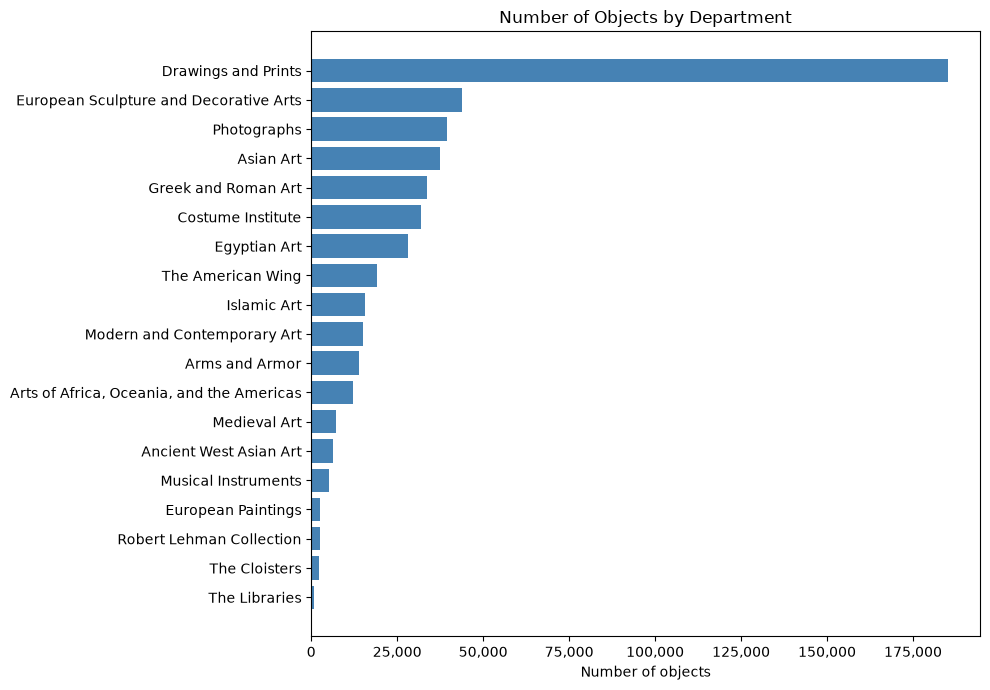

In [170]:
#  number of objects in each department, largest at the top
dept_counts = met_df['Department'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(dept_counts.index, dept_counts.values, color='steelblue')
ax.set_title('Number of Objects by Department')
ax.set_xlabel('Number of objects')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

### Visualization 2: Line Chart
The number of objects the museum acquired each year, based on the accession year.

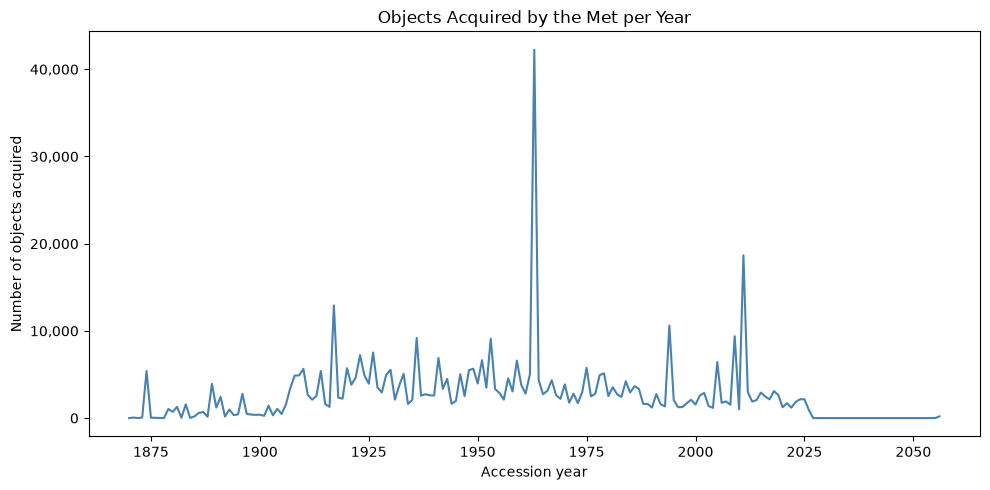

In [171]:
# Line chart: number of objects the museum acquired each year (the Met was founded in 1870)
per_year = met_df['AccessionYear'].value_counts().sort_index().loc[1870:]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(per_year.index, per_year.values, color='steelblue')
ax.set_title('Objects Acquired by the Met per Year')
ax.set_xlabel('Accession year')
ax.set_ylabel('Number of objects acquired')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

### Visualization 3: Histogram
The distribution of when the objects were made, using each object's begin date.

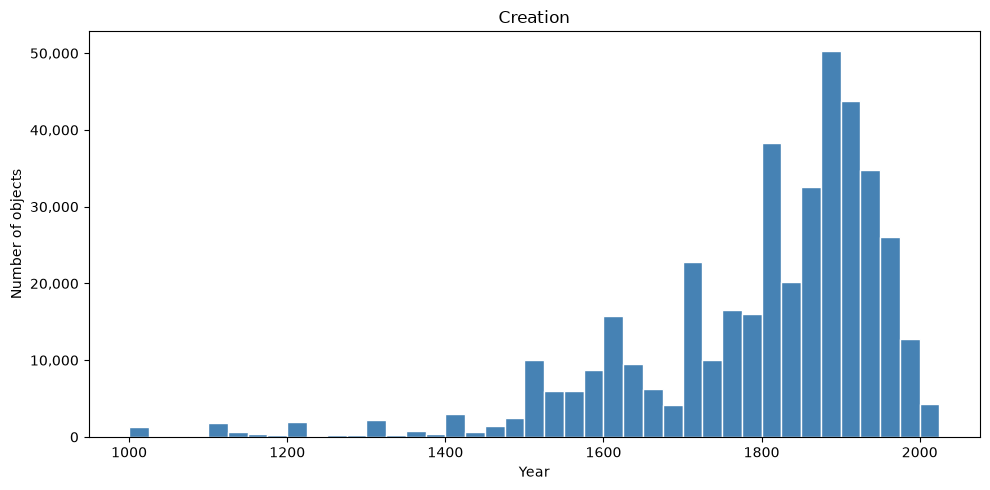

In [172]:
# Histogram: when the objects in the collection were made
# Limit to objects made from 1000 to 2025 so a few ancient objects do not squash the chart
dated = met_df[(met_df['Object Begin Date'] >= 1000) & (met_df['Object Begin Date'] <= 2025)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(dated['Object Begin Date'], bins=range(1000, 2050, 25), color='steelblue', edgecolor='white')
ax.set_title('Creation')
ax.set_xlabel('Year')
ax.set_ylabel('Number of objects')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()